# Explore image-parameter results

This notebook reads the summary CSV produced by `plot_image_params_results.py`; it does **not** open or process FITS files. Set `CSV_PATH` below to the existing `image_parameter_summary.csv`. Once FITS extraction has been done and the CSV is accessible, plotting is light enough to do locally without Slurm.

The notebook needs `pandas`, `matplotlib`, and `ipywidgets` (as well as `numpy`). If the controls do not render, enable/install the Jupyter widgets support in your notebook environment.

In [17]:
from pathlib import Path

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Update this to the summary CSV written by the FITS extraction run.
test_path = "parameter_plots_test2_finer_grid_multiscale_local_rms"
CSV_PATH = Path("/Users/gechen/soft_links/research_curtin/NIGHT_project/img_param_test/" + test_path + "/image_parameter_summary.csv")


In [18]:
CSV_PATH

PosixPath('/Users/gechen/soft_links/research_curtin/NIGHT_project/img_param_test/parameter_plots_test2_finer_grid_multiscale_local_rms/image_parameter_summary.csv')

In [20]:
if not CSV_PATH.is_file():
    raise FileNotFoundError(f"Summary CSV not found: {CSV_PATH.resolve()}")

results = pd.read_csv(CSV_PATH)
required_columns = {
    "obsnum", "robust", "minuv", "tukey", "rms_mjy_beam",
    "n_components_all", "n_components_flags0",
}
missing = required_columns - set(results.columns)
if missing:
    raise ValueError(f"CSV is missing required columns: {', '.join(sorted(missing))}")

for column in ("robust", "minuv", "tukey", "rms_mjy_beam",
               "n_components_all", "n_components_flags0"):
    results[column] = pd.to_numeric(results[column], errors="raise")
results["obsnum"] = results["obsnum"].astype(str)

print(f"Loaded {len(results):,} runs from {CSV_PATH.resolve()}")
results.head()


Loaded 7,426 runs from /Users/gechen/Dropbox/Mac3_Air2025/DB_Documents_Mac3/Research_Curtin/NIGHT_project/img_param_test/parameter_plots_test2_finer_grid_multiscale_local_rms/image_parameter_summary.csv


,obsnum,robust,minuv,tukey,rms_mjy_beam,valid_rms_fraction,n_components_all,n_components_flags0,rms_file,catalogue_file
0,1437423080,-0.1,0.0,0.0,3.536095,1.0,9589,9568,/scratch/pawsey0272/gcchen/test3_image_paramet...,/scratch/pawsey0272/gcchen/test3_image_paramet...
1,1437423080,-0.1,0.0,100.0,3.538592,1.0,9585,9564,/scratch/pawsey0272/gcchen/test3_image_paramet...,/scratch/pawsey0272/gcchen/test3_image_paramet...
2,1437423080,-0.1,0.0,200.0,3.540582,1.0,9588,9562,/scratch/pawsey0272/gcchen/test3_image_paramet...,/scratch/pawsey0272/gcchen/test3_image_paramet...
3,1437423080,-0.1,0.0,400.0,3.547289,1.0,9565,9543,/scratch/pawsey0272/gcchen/test3_image_paramet...,/scratch/pawsey0272/gcchen/test3_image_paramet...
4,1437423080,-0.1,0.0,50.0,3.537100,1.0,9589,9569,/scratch/pawsey0272/gcchen/test3_image_paramet...,/scratch/pawsey0272/gcchen/test3_image_paramet...


## Interactive plots

Choose one observation or all observations. Adjust the robust range and minimum-UV maximum to zoom the horizontal axes. These are display limits; the source CSV is not changed.

In [21]:
PARAMS = ("robust", "minuv", "tukey")
LABELS = {
    "robust": "Briggs robust",
    "minuv": "Minimum UV distance (wavelengths)",
    "tukey": "Inner Tukey taper (wavelengths)",
}
observations = sorted(results["obsnum"].unique())
observation = widgets.Dropdown(
    options=[("All observations", "All")] + [(obs, obs) for obs in observations],
    value="All",
    description="Observation:",
    layout=widgets.Layout(width="350px"),
)
count_metric = widgets.Dropdown(
    options=[("Components with flags = 0", "n_components_flags0"),
             ("All catalogue components", "n_components_all")],
    value="n_components_flags0",
    description="Counts:",
    layout=widgets.Layout(width="350px"),
)
robust_range = widgets.FloatRangeSlider(
    value=[float(results.robust.min()), float(results.robust.max())],
    min=float(results.robust.min()), max=float(results.robust.max()),
    step=max((float(results.robust.max()) - float(results.robust.min())) / 200, 0.001),
    description="Robust:", readout_format=".3g", continuous_update=False,
    layout=widgets.Layout(width="600px"),
)
minuv_max = widgets.FloatSlider(
    value=float(results.minuv.max()), min=float(results.minuv.min()),
    max=float(results.minuv.max()), step=max(float(results.minuv.max() - results.minuv.min()) / 200, 0.01),
    description="Minuv max:", readout_format=".3g", continuous_update=False,
    layout=widgets.Layout(width="600px"),
)

def plot_results(observation, count_metric, robust_range, minuv_max):
    selected = results if observation == "All" else results[results.obsnum == observation]
    if selected.empty:
        print("No rows match this selection.")
        return

    fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
    for col, param in enumerate(PARAMS):
        other_params = [name for name in PARAMS if name != param]
        group_columns = other_params + ([] if observation != "All" else ["obsnum"])
        for axis, metric in zip(axes[:, col], ("rms_mjy_beam", count_metric)):
            for _, group in selected.groupby(group_columns, dropna=False):
                group = group.sort_values(param)
                axis.plot(group[param], group[metric], color="0.65",
                          linewidth=0.6, alpha=0.5)
            axis.scatter(selected[param], selected[metric], s=13,
                         alpha=0.5, color="tab:blue")
            medians = selected.groupby(param, as_index=False)[metric].median().sort_values(param)
            axis.plot(medians[param], medians[metric], "o-", color="tab:orange",
                      linewidth=2, label="Median over other settings")
            if param == "robust":
                axis.set_xlim(*robust_range)
            elif param == "minuv":
                axis.set_xlim(right=minuv_max)
            axis.set_xlabel(LABELS[param])
            axis.grid(alpha=0.2)
        axes[0, col].set_ylabel("Median map RMS (mJy/beam)")
        axes[1, col].set_ylabel(
            "Components (flags = 0)" if count_metric == "n_components_flags0"
            else "All catalogue components"
        )
    axes[0, 0].legend(fontsize=8)
    title = "All observations" if observation == "All" else f"Observation {observation}"
    fig.suptitle(f"{title} — {len(selected)} evaluated combinations\n"
                 "Points: individual runs; grey lines: other settings fixed.", fontsize=12)
    plt.show()

controls = widgets.VBox([
    widgets.HBox([observation, count_metric]),
    robust_range,
    minuv_max,
])
display(controls)
plot_output = widgets.interactive_output(
    plot_results,
    {"observation": observation, "count_metric": count_metric,
     "robust_range": robust_range, "minuv_max": minuv_max},
)
display(plot_output)


Output()

## Save a plot

To save the currently selected view, run the cell below. It writes a PNG into the current working directory. Change `PNG_PATH` if you want it somewhere else.

In [22]:
PNG_PATH = Path("image_parameter_exploration.png")

def save_current_view(path=PNG_PATH):
    selected = results if observation.value == "All" else results[results.obsnum == observation.value]
    if selected.empty:
        raise ValueError("No rows match the current observation selection.")
    fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
    metric = count_metric.value
    for col, param in enumerate(PARAMS):
        other_params = [name for name in PARAMS if name != param]
        group_columns = other_params + ([] if observation.value != "All" else ["obsnum"])
        for axis, y_metric in zip(axes[:, col], ("rms_mjy_beam", metric)):
            for _, group in selected.groupby(group_columns, dropna=False):
                group = group.sort_values(param)
                axis.plot(group[param], group[y_metric], color="0.65", linewidth=0.6, alpha=0.5)
            axis.scatter(selected[param], selected[y_metric], s=13, alpha=0.5, color="tab:blue")
            medians = selected.groupby(param, as_index=False)[y_metric].median().sort_values(param)
            axis.plot(medians[param], medians[y_metric], "o-", color="tab:orange", linewidth=2)
            if param == "robust":
                axis.set_xlim(*robust_range.value)
            elif param == "minuv":
                axis.set_xlim(right=minuv_max.value)
            axis.set_xlabel(LABELS[param])
            axis.grid(alpha=0.2)
        axes[0, col].set_ylabel("Median map RMS (mJy/beam)")
        axes[1, col].set_ylabel("Components (flags = 0)" if metric == "n_components_flags0"
                                else "All catalogue components")
    axes[0, 0].legend(fontsize=8)
    title = "All observations" if observation.value == "All" else f"Observation {observation.value}"
    fig.suptitle(f"{title} — {len(selected)} evaluated combinations", fontsize=12)
    fig.savefig(path, dpi=160)
    plt.close(fig)
    print(f"Saved {path.resolve()}")

save_current_view()


/var/folders/l4/3h34w0390lsbgrl_sbf6915h0000gn/T/ipykernel_57425/396813067.py:28: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0, 0].legend(fontsize=8)


Saved /Users/gechen/Dropbox/Mac3_Air2025/DB_Documents_Mac3/Research_Curtin/NIGHT_project/night_light_code_laptop/image_parameter_exploration.png


## Briggs Results: use the most frequent "best" choice (CSV saved)

In [23]:
# Median over minuv and taper, for each observation and Briggs value.
medians = results.groupby(["obsnum", "robust"])[
    ["rms_mjy_beam", "n_components_flags0"]
].median().reset_index()

rows = []
for obsnum, group in medians.groupby("obsnum"):
    for metric, direction in [
        ("rms_mjy_beam", "min"),
        ("n_components_flags0", "max"),
    ]:
        best = group[metric].min() if direction == "min" else group[metric].max()

        # Keep all values if there is an exact tie.
        for robust in group.loc[group[metric] == best, "robust"]:
            rows.append({
                "obsnum": obsnum,
                "metric": metric,
                "best_briggs": robust,
                "best_median": best,
            })

best_briggs = pd.DataFrame(rows)

frequency = (
    best_briggs.groupby(["metric", "best_briggs"])
    .size()
    .reset_index(name="n_observations")
)

# Save beside the input summary CSV.
best_briggs.to_csv(CSV_PATH.parent / "best_briggs_by_obs.csv", index=False)
frequency.to_csv(CSV_PATH.parent / "best_briggs_frequency.csv", index=False)

display(best_briggs)
display(frequency)
print(f"Saved in: {CSV_PATH.parent}")

,obsnum,metric,best_briggs,best_median
0,1437423080,rms_mjy_beam,0.1,3.445253
1,1437423080,n_components_flags0,0.1,9697.000000
2,1441747424,rms_mjy_beam,0.0,2.386887
3,1441747424,n_components_flags0,0.0,13295.000000
4,1442350624,rms_mjy_beam,0.2,3.394507
5,1442350624,n_components_flags0,0.1,10357.000000
6,1442350624,n_components_flags0,0.2,10357.000000
7,1444763232,rms_mjy_beam,0.3,3.157516
8,1444763232,n_components_flags0,0.3,10290.000000
9,1447262000,rms_mjy_beam,0.0,2.484458


,metric,best_briggs,n_observations
0,n_components_flags0,-0.1,4
1,n_components_flags0,0.0,4
2,n_components_flags0,0.1,2
3,n_components_flags0,0.2,1
4,n_components_flags0,0.3,1
5,rms_mjy_beam,-0.1,1
6,rms_mjy_beam,0.0,6
7,rms_mjy_beam,0.1,2
8,rms_mjy_beam,0.2,1
9,rms_mjy_beam,0.3,1


Saved in: /Users/gechen/soft_links/research_curtin/NIGHT_project/img_param_test/parameter_plots_test2_finer_grid_multiscale_local_rms


## Fix Briggs = 0, compare UV cut and taper (plots saved)

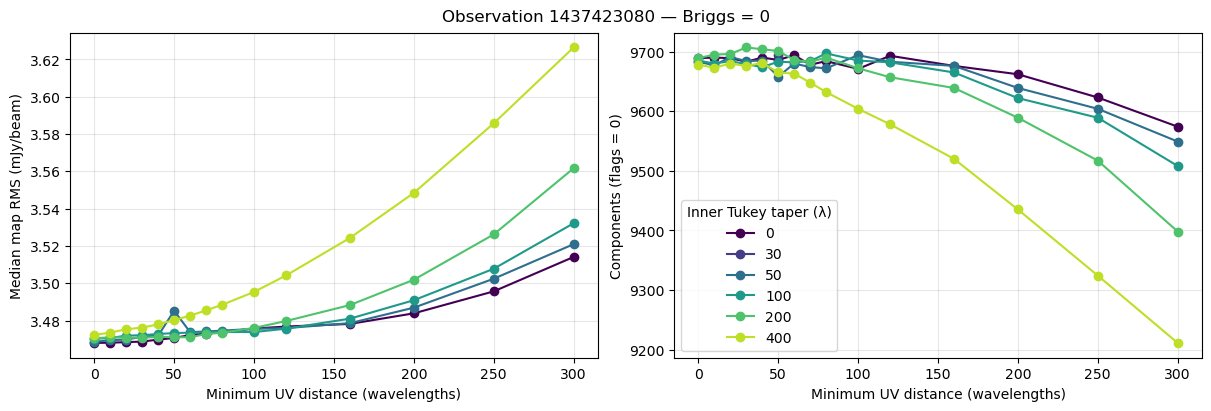

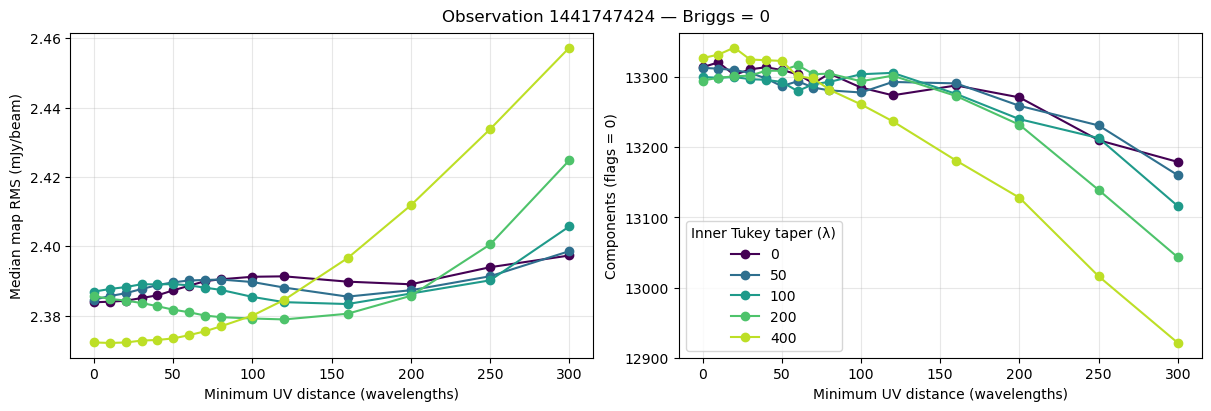

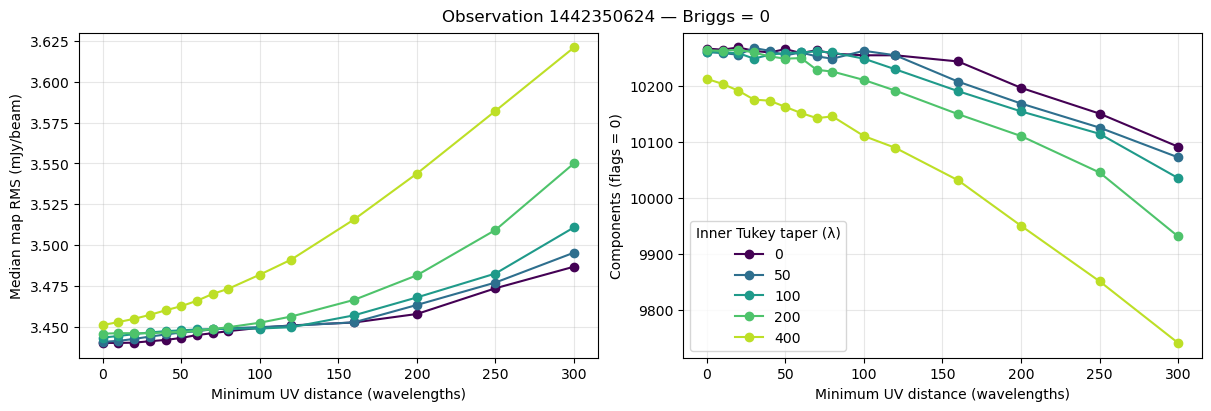

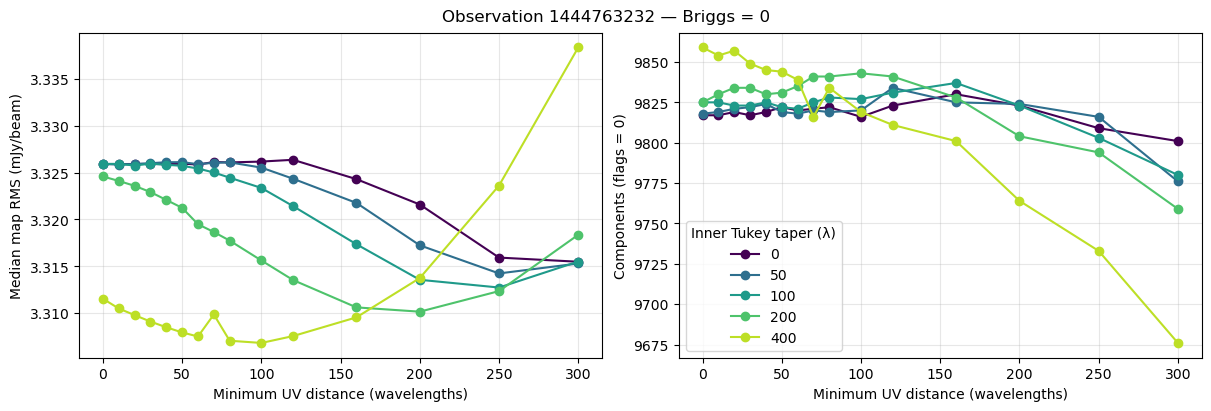

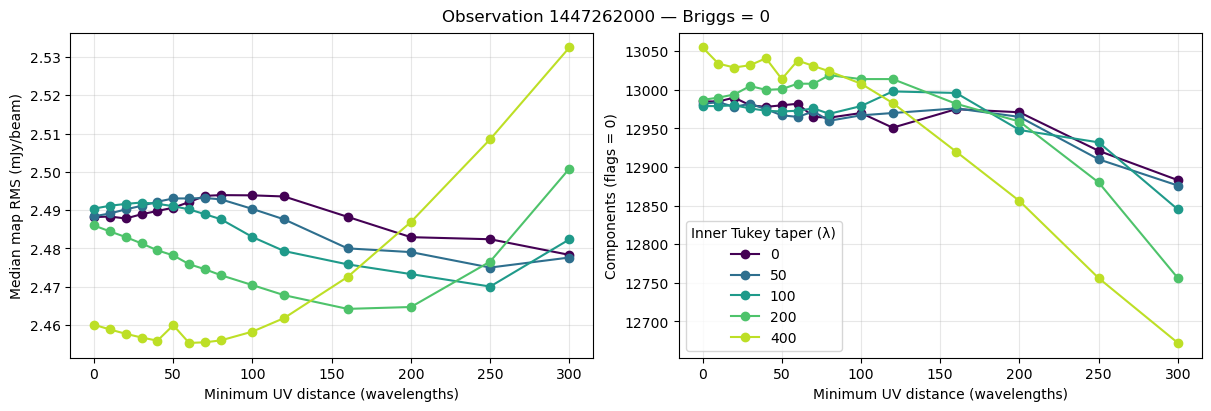

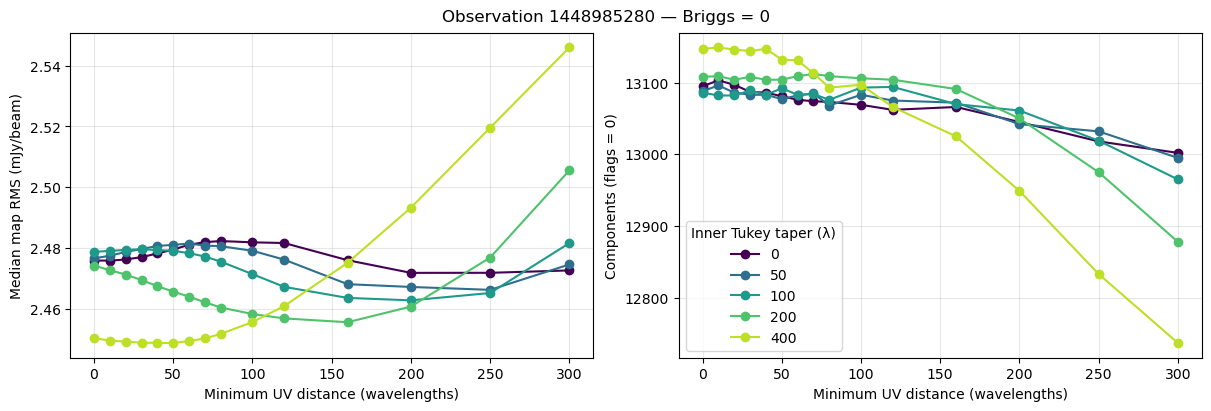

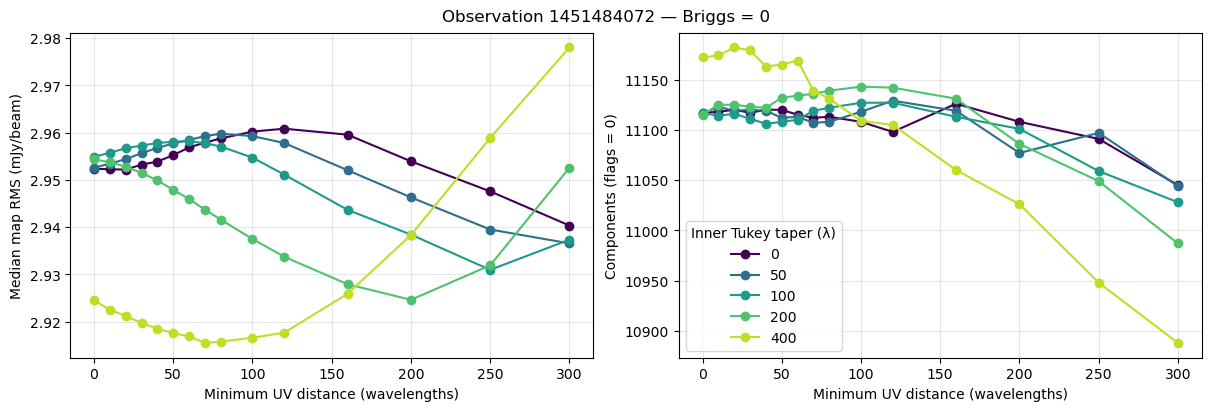

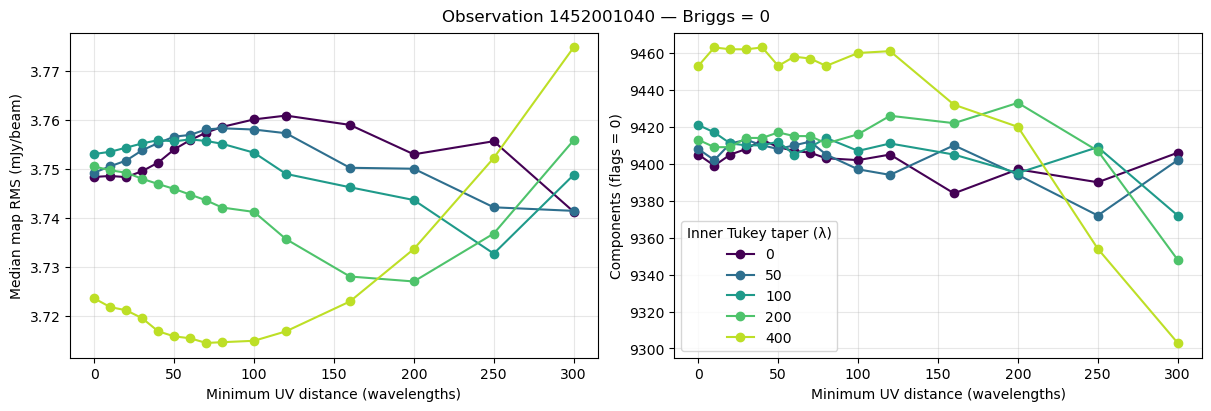

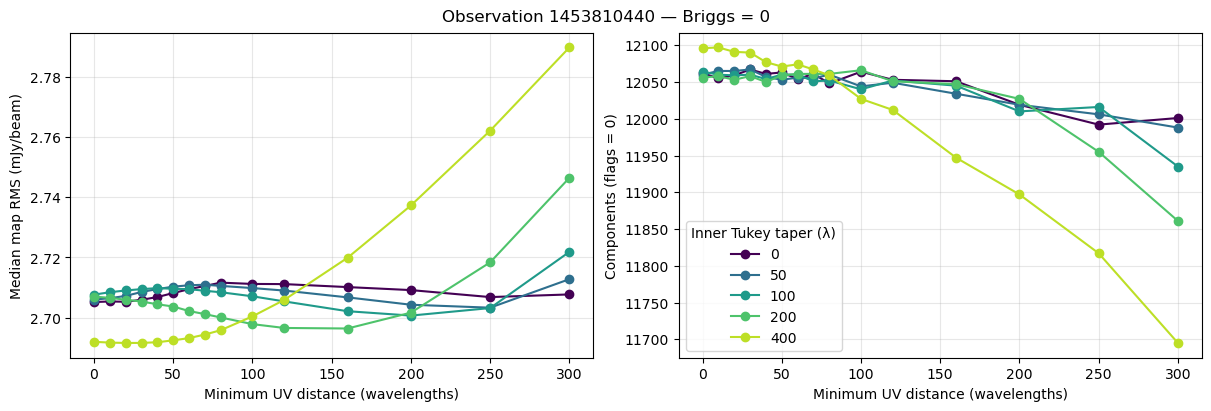

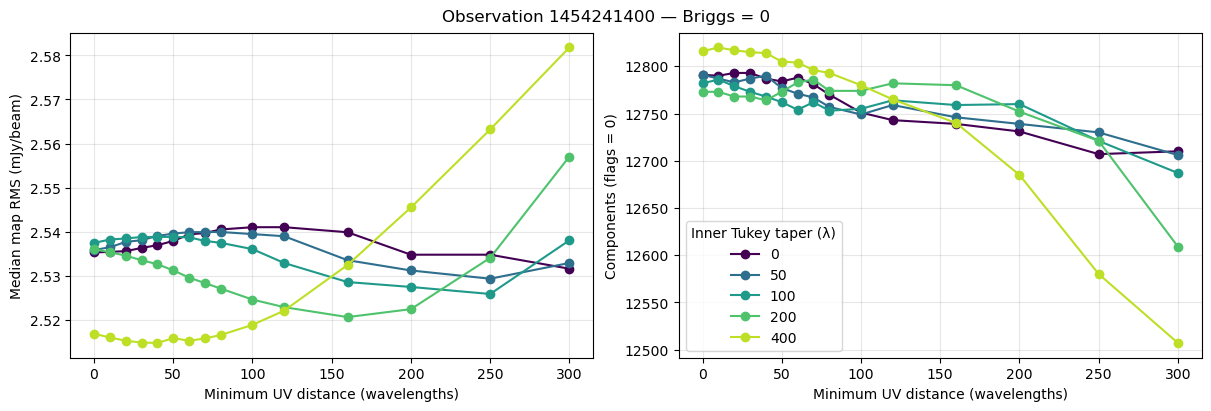

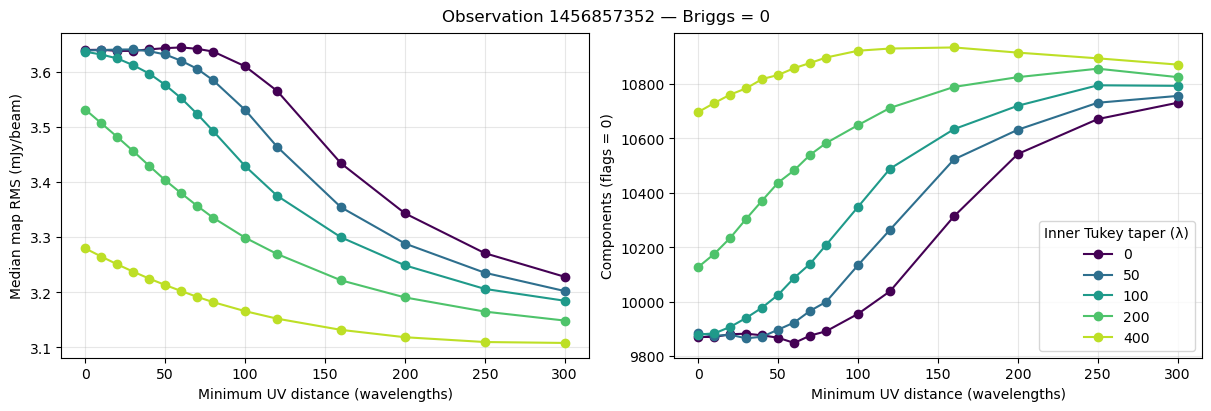

Plots saved in: /Users/gechen/Dropbox/Mac3_Air2025/DB_Documents_Mac3/Research_Curtin/NIGHT_project/img_param_test/parameter_plots_test2_finer_grid_multiscale_local_rms/briggs_0_uvmin_taper


In [24]:
fixed_briggs = 0.0
plot_dir = CSV_PATH.parent / f"briggs_{fixed_briggs:g}_uvmin_taper"
plot_dir.mkdir(parents=True, exist_ok=True)

selected = results[
    np.isclose(results["robust"], fixed_briggs)
].copy()

if selected.empty:
    raise ValueError(f"No results for Briggs = {fixed_briggs}")

taper_values = sorted(selected["tukey"].unique())
colors = dict(zip(
    taper_values,
    plt.cm.viridis(np.linspace(0, 0.9, len(taper_values)))
))

for obsnum, group in selected.groupby("obsnum"):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)

    for taper, curve in group.groupby("tukey"):
        curve = curve.sort_values("minuv")

        axes[0].plot(
            curve["minuv"], curve["rms_mjy_beam"],
            "o-", color=colors[taper], label=f"{taper:g}"
        )
        axes[1].plot(
            curve["minuv"], curve["n_components_flags0"],
            "o-", color=colors[taper], label=f"{taper:g}"
        )

    axes[0].set_ylabel("Median map RMS (mJy/beam)")
    axes[1].set_ylabel("Components (flags = 0)")

    for ax in axes:
        ax.set_xlabel("Minimum UV distance (wavelengths)")
        ax.grid(alpha=0.3)

    axes[1].legend(title="Inner Tukey taper (λ)")
    fig.suptitle(f"Observation {obsnum} — Briggs = {fixed_briggs:g}")
    
    fig.savefig(
    plot_dir / f"{obsnum}_briggs_{fixed_briggs:g}_uvmin_taper.png",
    dpi=200,
    bbox_inches="tight",
    )
    
    plt.show()

print(f"Plots saved in: {plot_dir.resolve()}")

## Each obs have different responses to UV cutoff & taper. Ask Natasha for comments.
* 1437423080 and 1442350624: small minuv and small taper perform well; stronger cuts generally worsen both metrics.
* Most other observations: taper = 400 with low minuv slightly improves RMS and often component count. However, the improvements are small—typically around 0.5–1.5% in RMS compared with no cut/taper. The narrow vertical axes make these differences look dramatic.
* 1456857352 is the clear exception: suppressing short baselines produces a much larger improvement. It should remain in the comparison, but its behaviour should also be shown separately.
* Large minuv combined with large taper generally loses components in the other ten observations.

## Combine all 11 obs to explore rms & component vs minuv & taper
### Relative RMS and component count
For each observation, use its image with **Briggs = 0, minuv = 0, and taper = 0**
as the reference.

$$
\Delta \mathrm{RMS}\;(\%) =
\frac{\mathrm{RMS}(\mathrm{minuv}, \mathrm{taper}) - \mathrm{RMS}(0,0)}
{\mathrm{RMS}(0,0)}
$$

$$
\Delta N_{\mathrm{comp}}\;(\%) =
\frac{N_{\mathrm{comp}}(\mathrm{minuv}, \mathrm{taper}) - {N_{\mathrm{comp}}(0,0)}}
{N_{\mathrm{comp}}(0,0)}
$$

- **Negative relative RMS:** lower noise than the reference.
- **Positive relative component count:** more detected components with flags = 0.
  This does not necessarily mean more real sources.

The combined heatmaps show the **median percentage change across observations**
at each minuv–taper pair, with Briggs fixed at 0.


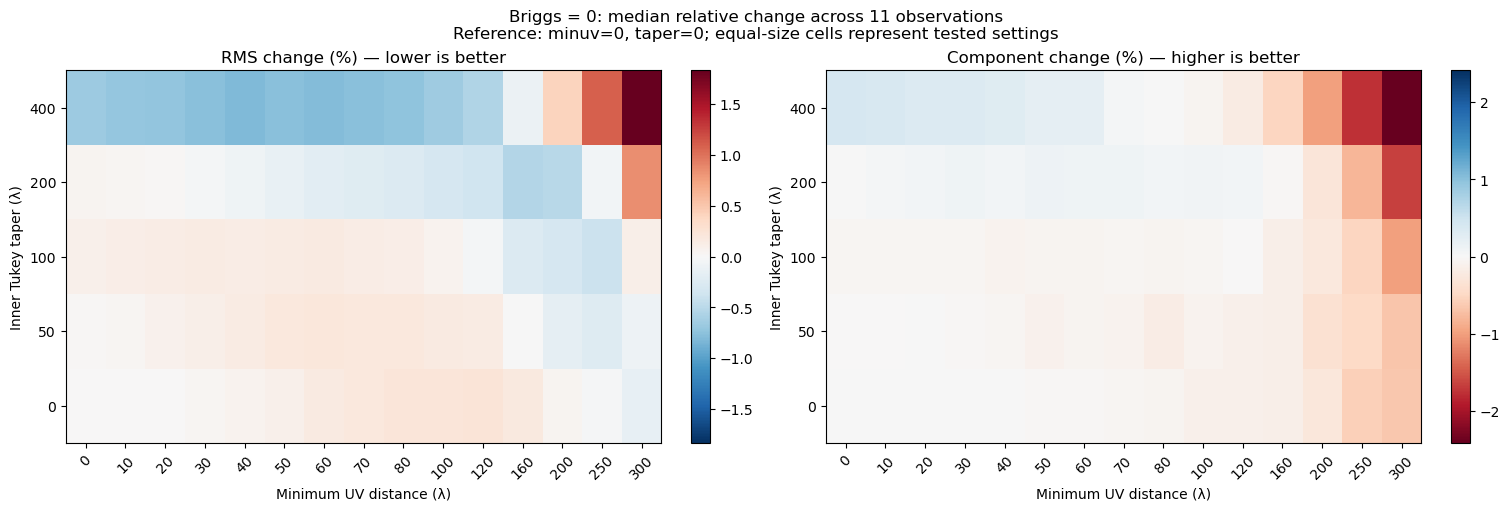

In [25]:
# Briggs = 0: compare each observation with its own no-cut/no-taper result.
data = results[np.isclose(results["robust"], 0)].copy()
keys = ["obsnum", "minuv", "tukey"]

if data.duplicated(keys).any():
    raise ValueError("Duplicate parameter combinations: check the input CSV.")

reference = data[
    np.isclose(data["minuv"], 0) & np.isclose(data["tukey"], 0)
][["obsnum", "rms_mjy_beam", "n_components_flags0"]].rename(columns={
    "rms_mjy_beam": "reference_rms",
    "n_components_flags0": "reference_count",
})

if reference["obsnum"].nunique() != data["obsnum"].nunique():
    raise ValueError("Some observations lack the minuv=0, taper=0 reference.")

data = data.merge(reference, on="obsnum", validate="many_to_one")
data["rms_change_pct"] = 100 * (
    data["rms_mjy_beam"] / data["reference_rms"] - 1
)
data["count_change_pct"] = 100 * (
    data["n_components_flags0"] / data["reference_count"] - 1
)

summary = data.groupby(["minuv", "tukey"]).agg(
    rms_change_pct=("rms_change_pct", "median"),
    count_change_pct=("count_change_pct", "median"),
    n_rms=("rms_change_pct", "count"),
    n_count=("count_change_pct", "count"),
).reset_index()

# Compare the same set of observations in every displayed cell.
n_obs = data["obsnum"].nunique()
summary = summary[
    (summary["n_rms"] == n_obs) & (summary["n_count"] == n_obs)
].copy()

plot_dir = CSV_PATH.parent / "briggs_0_uvmin_taper"
plot_dir.mkdir(parents=True, exist_ok=True)
summary.to_csv(plot_dir / "combined_relative_results.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)

for ax, metric, title, cmap in [
    (axes[0], "rms_change_pct", "RMS change (%) — lower is better", "RdBu_r"),
    (axes[1], "count_change_pct", "Component change (%) — higher is better", "RdBu"),
]:
    table = summary.pivot(index="tukey", columns="minuv", values=metric)
    table = table.sort_index().sort_index(axis=1)

    limit = max(np.nanmax(np.abs(table.to_numpy())), 0.01)
    im = ax.imshow(
        table.to_numpy(), origin="lower", aspect="auto",
        interpolation="nearest", cmap=cmap, vmin=-limit, vmax=limit,
    )

    ax.set_xticks(range(len(table.columns)))
    ax.set_xticklabels([f"{x:g}" for x in table.columns], rotation=45)
    ax.set_yticks(range(len(table.index)))
    ax.set_yticklabels([f"{x:g}" for x in table.index])
    ax.set_xlabel("Minimum UV distance (λ)")
    ax.set_ylabel("Inner Tukey taper (λ)")
    ax.set_title(title)
    fig.colorbar(im, ax=ax)

fig.suptitle(
    f"Briggs = 0: median relative change across {n_obs} observations\n"
    "Reference: minuv=0, taper=0; equal-size cells represent tested settings"
)
fig.savefig(plot_dir / "combined_relative_heatmaps.png", dpi=200)
plt.show()